# 08 · Loss Given Default, Exposure at Default and Expected Loss

| | |
|---|---|
| **Question** | When a borrower defaults, how much does Meridian lose, and what is the expected loss of the whole book in dollars? |
| **Inputs** | `gold.mart_lgd_base` (184,079 seasoned defaults), the PD challenger (notebook 07) |
| **Outputs** | LGD and EAD parameters, Expected Loss for the 2016 book with a backtest, Expected Loss for the live book |
| **Skills shown** | Fractional-response regression (fractional logit), segment analysis, downturn LGD, amortisation maths, Expected Loss backtesting |

### The Expected Loss formula

$$EL = PD \times LGD \times EAD$$

| Component | Meaning | Source |
|---|---|---|
| **PD** | Probability the borrower defaults over the life of the loan | Challenger model (notebook 07), converted from 24 months to lifetime |
| **LGD** | Share of the exposure lost after recoveries | This notebook |
| **EAD** | Amount still owed at the moment of default | This notebook |

Expected Loss is what the CFO books as a loss provision (IFRS 9 / CECL) and what pricing must cover. It is the bridge between a statistical model and the income statement.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error

from meridian import config, viz
from meridian.data import TARGET, load_pd_split
from meridian.db import connect

viz.set_style()
con = connect()
MODELS_DIR = config.PROJECT_ROOT / "models"
REPORTS = config.PROJECT_ROOT / "reports"
lgd = con.execute("select * from gold.mart_lgd_base").df()
lgd["default_year"] = pd.to_datetime(lgd.est_default_month).dt.year
print(f"Seasoned defaults: {len(lgd):,}   mean LGD {lgd.loss_given_default.mean():.1%}   mean EAD ratio {lgd.ead_ratio.mean():.1%}")

Seasoned defaults: 184,079   mean LGD 89.7%   mean EAD ratio 71.7%


Only defaults whose recoveries have had at least 12 months to come in are used ("seasoned"), as defined in `int_loans__outcomes.sql`. Using fresh defaults would understate recoveries and overstate LGD.

## 1. Loss Given Default

### 1.1 Distribution

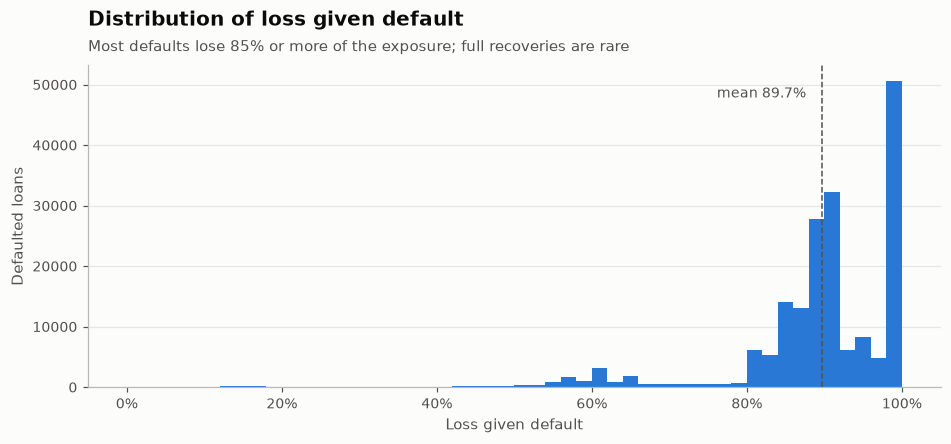

,share_of_defaults
LGD of 100% (nothing recovered),25.7%
LGD between 80% and 100%,65.9%
LGD below 80%,8.4%


In [2]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(lgd.loss_given_default, bins=50, color=viz.BLUE)
ax.axvline(lgd.loss_given_default.mean(), color=viz.INK_2, ls="--", lw=1)
ax.text(lgd.loss_given_default.mean() - 0.01, ax.get_ylim()[1] * 0.9, f"mean {lgd.loss_given_default.mean():.1%}  ",
        ha="right", fontsize=9, color=viz.INK_2)
viz.pct(ax, axis="x")
ax.set_xlabel("Loss given default")
ax.set_ylabel("Defaulted loans")
ax.set_title("Distribution of loss given default")
viz.subtitle(ax, "Most defaults lose 85% or more of the exposure; full recoveries are rare")
plt.show()

shares = pd.Series({"LGD of 100% (nothing recovered)": (lgd.loss_given_default >= 0.999).mean(),
                    "LGD between 80% and 100%": lgd.loss_given_default.between(0.8, 0.999).mean(),
                    "LGD below 80%": (lgd.loss_given_default < 0.8).mean()})
shares.to_frame("share_of_defaults").style.format("{:.1%}")

Unsecured consumer debt has no collateral. After charge-off, Lending Club collected small amounts and often sold the debt to collection agencies for cents on the dollar. The result is an LGD concentrated near 90%.

### 1.2 Does LGD vary by segment?

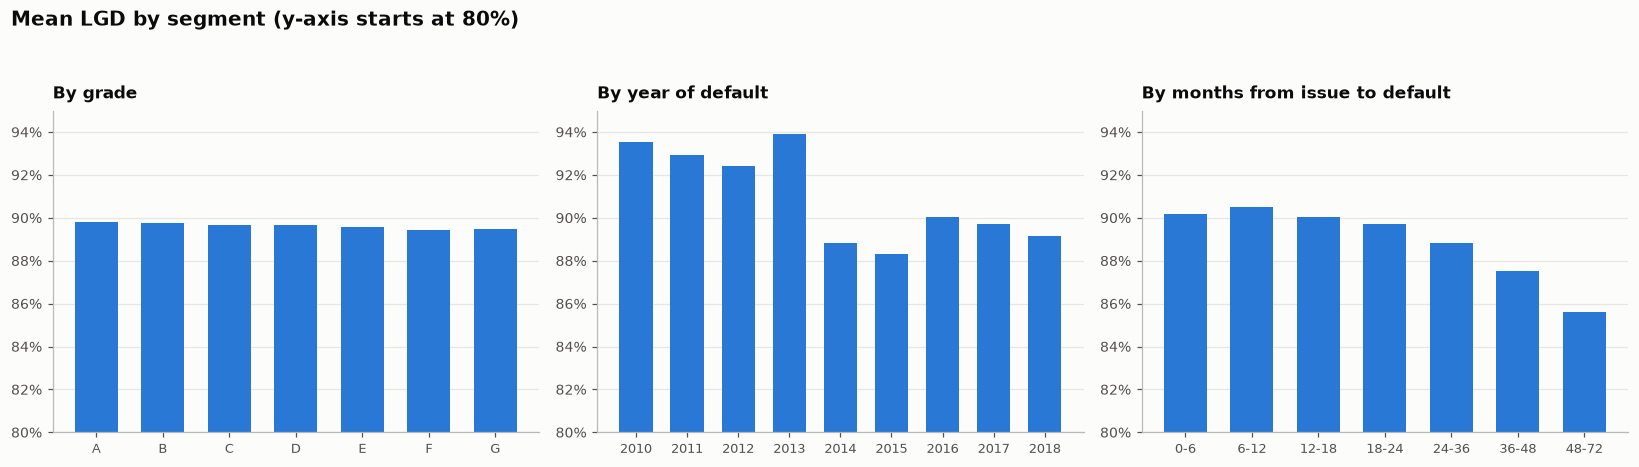

In [3]:
def seg(col):
    g = lgd.groupby(col, observed=True).agg(defaults=("loss_given_default", "size"), mean_lgd=("loss_given_default", "mean"))
    return g[g.defaults >= 500]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in [(axes[0], "grade", "By grade"), (axes[1], "default_year", "By year of default"),
                       (axes[2], "months_to_default", "By months from issue to default")]:
    g = seg(col)
    if col == "months_to_default":
        g = lgd.assign(b=pd.cut(lgd.months_to_default, [0, 6, 12, 18, 24, 36, 48, 72])).groupby("b", observed=True) \
               .loss_given_default.agg(["size", "mean"]).rename(columns={"size": "defaults", "mean": "mean_lgd"})
        labels = [f"{int(i.left)}-{int(i.right)}" for i in g.index]
    else:
        labels = g.index.astype(str)
    ax.bar(range(len(g)), g.mean_lgd, color=viz.BLUE, width=0.65)
    ax.set_xticks(range(len(g)), labels, fontsize=8.5)
    ax.set_ylim(0.8, 0.95)
    viz.pct(ax)
    ax.set_title(title, fontsize=11, pad=8)
fig.suptitle("Mean LGD by segment (y-axis starts at 80%)", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.05)
fig.tight_layout()
plt.show()

**What it means:** LGD moves only a few percentage points across segments.

- **Grade:** flat at about 90%. How risky a borrower looked at origination says nothing about what is recovered after default.
- **Year of default:** 93 to 94% for defaults in 2010 to 2013, about 89% from 2014 onwards, consistent with Lending Club's collections improving as it scaled.
- **Age at default:** loans that default late in life lose a little less (86% after month 48), because collectors recover more from borrowers who had already repaid most of the loan and showed willingness to pay.

### 1.3 Can a model predict LGD?

A **fractional logit** (a GLM with a binomial family and logit link) is the standard model for a target bounded between 0 and 1. It is fitted on defaults from loans issued up to 2014 and tested on loans issued in 2015.

In [4]:
lgd["log_funded"] = np.log(lgd.funded_amount)
# Joint applications carry zero individual income and 9 loans lack DTI: excluded from the regression only.
model_rows = lgd[(lgd.annual_income > 0) & lgd.debt_to_income.notna()]
train_l = model_rows[model_rows.dataset_split == "train"].copy()
test_l = model_rows[model_rows.dataset_split == "validation"].copy()
print(f"Regression sample: {len(train_l):,} train defaults (loans issued to 2014), {len(test_l):,} test defaults (2015)")

formula = ("loss_given_default ~ C(grade) + C(term_months) + C(home_ownership) + log_funded + interest_rate"
           " + fico_score + debt_to_income + np.log(annual_income) + months_to_default")
glm = smf.glm(formula, data=train_l, family=sm.families.Binomial()).fit(cov_type="HC1")
pred_glm = glm.predict(test_l)
mean_only = np.full(len(test_l), train_l.loss_given_default.mean())

pd.DataFrame({
    "Train mean (no model)": {"MAE": mean_absolute_error(test_l.loss_given_default, mean_only),
                              "rank_correlation": np.nan,
                              "predicted_mean": mean_only.mean()},
    "Fractional logit": {"MAE": mean_absolute_error(test_l.loss_given_default, pred_glm),
                         "rank_correlation": spearmanr(test_l.loss_given_default, pred_glm)[0],
                         "predicted_mean": pred_glm.mean()},
    "Observed (2015 loans)": {"MAE": np.nan, "rank_correlation": np.nan, "predicted_mean": test_l.loss_given_default.mean()},
}).T.style.format("{:.4f}", na_rep="")

Regression sample: 74,570 train defaults (loans issued to 2014), 61,829 test defaults (2015)


,MAE,rank_correlation,predicted_mean
Train mean (no model),0.0762,,0.8920
Fractional logit,0.0744,0.1133,0.8975
Observed (2015 loans),,,0.8972


**Honest result:** the fractional logit barely beats a single average. Its rank correlation with actual LGD is weak and its error is almost identical to predicting the mean for everyone. Borrower characteristics at origination tell very little about what will be recovered after default, because recoveries depend mainly on the collection process, not on the borrower's profile.

**Decision:** use a **segment-level LGD** (by term, the one split with a stable difference) instead of a loan-level model, and apply a **downturn adjustment**. A model that adds complexity without accuracy fails the first rule of model risk management.

### 1.4 Downturn LGD

Regulators (Basel) require LGD that reflects an economic downturn, because recoveries fall when many borrowers default at once. The book has no recession-era defaults of meaningful size, so the worst observed year (2013, when collections were weakest) is used as a conservative downturn proxy.

In [5]:
by_year = lgd.groupby("default_year").agg(defaults=("loss_given_default", "size"), mean_lgd=("loss_given_default", "mean"))
by_year = by_year[by_year.defaults >= 1000]
long_run = (lgd.loss_given_default * lgd.exposure_at_default).sum() / lgd.exposure_at_default.sum()
downturn = by_year.mean_lgd.max()
lgd_by_term = lgd.groupby("term_months").apply(
    lambda g: (g.loss_given_default * g.exposure_at_default).sum() / g.exposure_at_default.sum(), include_groups=False)
lgd_params = pd.DataFrame({"long_run_lgd": lgd_by_term,
                           "downturn_lgd": np.minimum(lgd_by_term + (downturn - long_run), 1.0)})
print(f"Exposure-weighted long-run LGD {long_run:.1%}; worst default year {by_year.mean_lgd.idxmax()} at {downturn:.1%}")
lgd_params.style.format("{:.1%}")

Exposure-weighted long-run LGD 89.8%; worst default year 2013 at 93.9%


,long_run_lgd,downturn_lgd
term_months,,
36,89.7%,93.8%
60,89.8%,94.0%


## 2. Exposure at Default

For an amortising loan, the balance outstanding at month *m* follows directly from the annuity schedule. The question is how close actual EAD is to the schedule, and what EAD to expect when the month of default is not yet known.

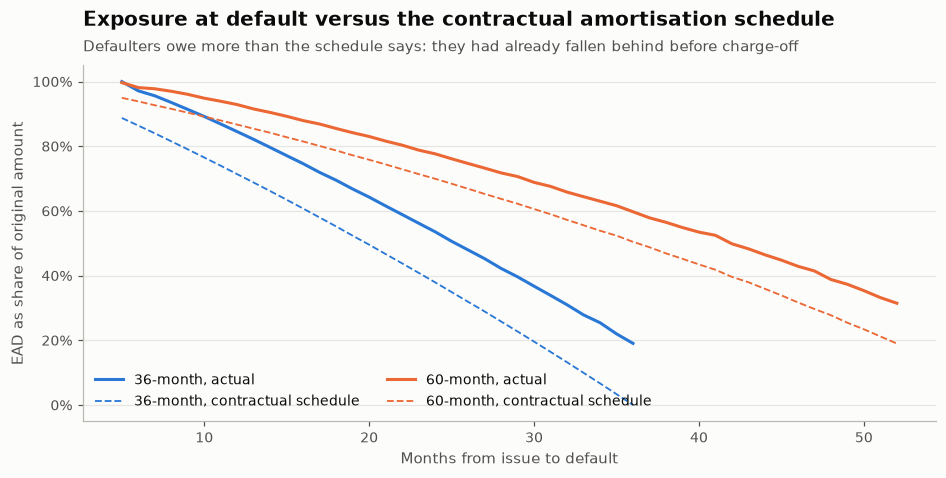

,defaults,mean_ead_ratio,median_months_to_default
term_months,,,
36,"112,682",66.3%,18
60,"71,397",80.4%,19


In [6]:
def scheduled_balance(rate, term, month):
    r = rate / 12
    return ((1 + r) ** term - (1 + r) ** np.minimum(month, term)) / ((1 + r) ** term - 1)

lgd["scheduled_ratio"] = scheduled_balance(lgd.interest_rate, lgd.term_months, lgd.months_to_default)
fig, ax = plt.subplots(figsize=(10, 4.2))
for term, color in [(36, viz.BLUE), (60, viz.ORANGE)]:
    g = lgd[lgd.term_months == term].groupby("months_to_default").agg(actual=("ead_ratio", "mean"),
                                                                      scheduled=("scheduled_ratio", "mean"), n=("ead_ratio", "size"))
    g = g[(g.n >= 100) & (g.index <= term)]
    ax.plot(g.index, g.actual, color=color, lw=2, label=f"{term}-month, actual")
    ax.plot(g.index, g.scheduled, color=color, lw=1.2, ls="--", label=f"{term}-month, contractual schedule")
viz.pct(ax)
ax.set_xlabel("Months from issue to default")
ax.set_ylabel("EAD as share of original amount")
ax.legend(loc="lower left", ncol=2)
ax.set_title("Exposure at default versus the contractual amortisation schedule")
viz.subtitle(ax, "Defaulters owe more than the schedule says: they had already fallen behind before charge-off")
plt.show()

ead_params = lgd.groupby("term_months").agg(defaults=("ead_ratio", "size"), mean_ead_ratio=("ead_ratio", "mean"),
                                            median_months_to_default=("months_to_default", "median"))
ead_params.style.format({"defaults": "{:,.0f}", "mean_ead_ratio": "{:.1%}", "median_months_to_default": "{:.0f}"})

**What it means:** actual exposure at default sits above the contractual schedule at every month, because defaulting borrowers typically miss several payments before charge-off, so less principal has been repaid than planned. At origination Meridian does not know when a borrower will default, so it uses the **average EAD ratio by term**: about two-thirds of the original amount for 36-month loans and more for 60-month loans, which amortise more slowly.

## 3. Expected Loss for the 2016 book, with a backtest

The challenger's 24-month PD is converted to a lifetime PD with a term-specific ratio measured on 2015 loans (lifetime defaults by the snapshot divided by 24-month defaults).

In [7]:
challenger = joblib.load(MODELS_DIR / "pd_challenger.joblib")
outcomes = con.execute("""
    select loan_id, is_defaulted, funded_amount, exposure_at_default, net_recoveries, grade
    from gold.fct_loans where dataset_split in ('validation', 'test_oot')""").df()
va = pd.read_parquet(config.DATA_DIR / "features" / "pd_validation.parquet").merge(outcomes, on="loan_id")
te = pd.read_parquet(config.DATA_DIR / "features" / "pd_test_oot.parquet").merge(outcomes, on="loan_id")

va["pd24"] = challenger.predict_pd(va)
lifetime_ratio = (va.groupby("term_months").is_defaulted.mean() / va.groupby("term_months").pd24.mean())
print("Lifetime / 24-month PD ratio by term (2015 loans):", lifetime_ratio.round(2).to_dict())

def expected_loss(df, downturn_lgd=False):
    pd_life = np.clip(challenger.predict_pd(df) * df.term_months.map(lifetime_ratio).values, 0, 1)
    lgd_col = "downturn_lgd" if downturn_lgd else "long_run_lgd"
    lgd_v = df.term_months.map(lgd_params[lgd_col]).values
    ead_v = df.funded_amount.values * df.term_months.map(ead_params.mean_ead_ratio).values
    return pd.DataFrame({"pd_lifetime": pd_life, "lgd": lgd_v, "ead": ead_v, "expected_loss": pd_life * lgd_v * ead_v},
                        index=df.index)

el = expected_loss(te)
te["expected_loss"] = el.expected_loss
te["realised_loss"] = np.where(te.is_defaulted, te.exposure_at_default - te.net_recoveries, 0.0)
print(f"2016 book: funded ${te.funded_amount.sum() / 1e9:.2f}B | expected loss ${te.expected_loss.sum() / 1e6:,.0f}M "
      f"({te.expected_loss.sum() / te.funded_amount.sum():.2%}) | realised loss to March 2019 "
      f"${te.realised_loss.sum() / 1e6:,.0f}M ({te.realised_loss.sum() / te.funded_amount.sum():.2%})")

Lifetime / 24-month PD ratio by term (2015 loans): {36: 1.58, 60: 1.83}


2016 book: funded $6.40B | expected loss $756M (11.81%) | realised loss to March 2019 $703M (10.99%)


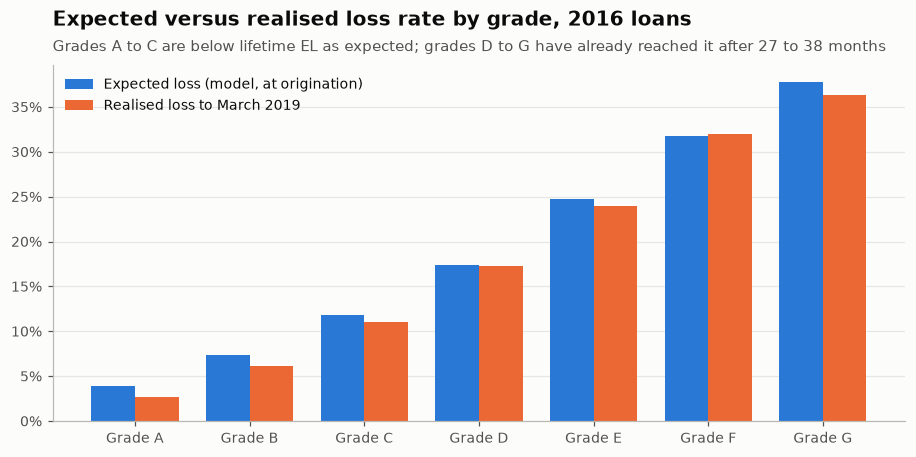

,funded,expected_loss,realised_loss,expected_loss_rate,realised_loss_rate
grade,,,,,
A,"$1,013,576,825","$39,020,170","$26,604,055",3.85%,2.62%
B,"$1,802,751,150","$132,646,775","$110,871,904",7.36%,6.15%
C,"$1,941,531,800","$229,111,258","$214,927,047",11.80%,11.07%
D,"$949,776,950","$165,148,672","$164,056,408",17.39%,17.27%
E,"$463,902,725","$114,501,000","$111,307,141",24.68%,23.99%
F,"$179,261,450","$56,849,801","$57,327,352",31.71%,31.98%
G,"$49,740,800","$18,777,090","$18,060,787",37.75%,36.31%


In [8]:
bt = te.groupby("grade").agg(funded=("funded_amount", "sum"), expected_loss=("expected_loss", "sum"),
                             realised_loss=("realised_loss", "sum"))
bt["expected_loss_rate"] = bt.expected_loss / bt.funded
bt["realised_loss_rate"] = bt.realised_loss / bt.funded

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(bt))
ax.bar(x - 0.19, bt.expected_loss_rate, 0.38, color=viz.BLUE, label="Expected loss (model, at origination)")
ax.bar(x + 0.19, bt.realised_loss_rate, 0.38, color=viz.ORANGE, label="Realised loss to March 2019")
ax.set_xticks(x, [f"Grade {g}" for g in bt.index])
viz.pct(ax)
ax.legend(loc="upper left")
ax.set_title("Expected versus realised loss rate by grade, 2016 loans")
viz.subtitle(ax, "Grades A to C are below lifetime EL as expected; grades D to G have already reached it after 27 to 38 months")
plt.show()
bt.style.format({"funded": "${:,.0f}", "expected_loss": "${:,.0f}", "realised_loss": "${:,.0f}",
                 "expected_loss_rate": "{:.2%}", "realised_loss_rate": "{:.2%}"})

**Reading the backtest:** Expected Loss is a *lifetime* figure. At the March 2019 snapshot, 2016 loans have been on the books for only 27 to 38 months, so realised losses should still sit *below* EL.

- **Grades A to C behave as expected:** realised losses are below EL and still accruing.
- **Grades D to G have already reached their lifetime EL**, with loans still outstanding. Final losses on the riskiest grades will exceed the model's expectation.

**Why:** the lifetime-to-24-month ratio was measured on 2015 loans, which were themselves only 39 to 50 months old at the snapshot, so it understates lifetime defaults, most of all for the 60-month loans that dominate grades D to G. On top of that, 2016 was a worse vintage than 2015.

**Action:** add a management overlay for grades D to G until the 2015 and 2016 vintages mature, and re-estimate the lifetime ratio every quarter. This backtest is repeated monthly in the monitoring pack (notebook 12). Finding under-reserving in a backtest and saying so is exactly what a model validation function is for.

## 4. Expected Loss for the live book

The live book is every loan still active at the snapshot (status Current, In Grace Period or Late). Its exposure is the outstanding principal today, and this is what Meridian's CFO would provision against.

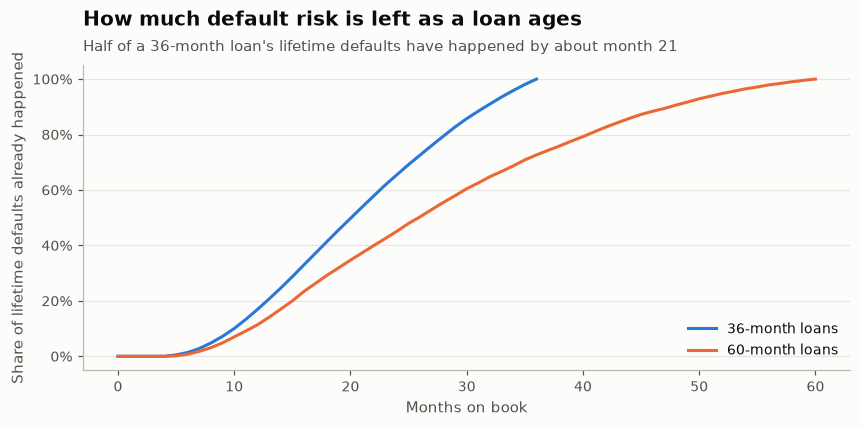

,loans,outstanding,expected_loss,downturn_el,el_rate,downturn_el_rate
grade,,,,,,
A,"197,601","$2,002,007,314","$126,684,347","$132,554,626",6.33%,6.62%
B,"268,457","$2,670,340,688","$288,221,804","$301,569,982",10.79%,11.29%
C,"263,663","$2,837,769,156","$438,414,759","$458,713,408",15.45%,16.16%
D,"119,080","$1,359,936,707","$292,650,147","$306,198,409",21.52%,22.52%
E,"39,559","$450,319,480","$111,693,695","$116,863,830",24.80%,25.95%
F,"8,990","$118,671,836","$35,543,482","$37,188,296",29.95%,31.34%
G,"2,683","$39,730,112","$13,604,454","$14,234,048",34.24%,35.83%
Total,"900,033","$9,478,775,294","$1,306,812,688","$1,367,322,598",13.79%,14.43%


In [9]:
live = con.execute("""
    select f.loan_id, f.issue_month, f.grade, f.term_months, f.funded_amount, f.loan_status,
           f.funded_amount - f.principal_repaid as outstanding_principal,
           datediff('month', f.issue_month, date '2019-03-01') as months_on_book
    from gold.fct_loans f
    where f.loan_status in ('Current', 'In Grace Period', 'Late (16-30 days)', 'Late (31-120 days)')
      and not f.is_policy_exception
""").df()

# Share of a vintage's lifetime defaults that has already happened by each month on book,
# from fully mature vintages (36-month: 2013-2015, 60-month: 2012-2013).
curves = con.execute("""
    select term_months, months_on_book, sum(cumulative_defaults) / sum(loans) as cdr
    from gold.mart_vintage_curves
    where (term_months = 36 and vintage_year between 2013 and 2015)
       or (term_months = 60 and vintage_year between 2012 and 2013)
    group by all order by all
""").df()
curves["share_elapsed"] = curves.cdr / curves.groupby("term_months").cdr.transform("max")
def elapsed_share(term, mob):
    c = curves[curves.term_months == term]
    return np.interp(mob, c.months_on_book, c.share_elapsed)
live["share_elapsed"] = [elapsed_share(t, m) for t, m in zip(live.term_months, live.months_on_book)]

feats = pd.concat([pd.read_parquet(config.DATA_DIR / "features" / f"pd_{s}.parquet")
                   for s in ["validation", "test_oot", "monitoring"]], ignore_index=True)
live = live.merge(feats.drop(columns=["issue_month", "term_months"]), on="loan_id")
pd_life = np.clip(challenger.predict_pd(live) * live.term_months.map(lifetime_ratio).values, 0, 0.99)
# Conditional PD over the remaining life, given the loan has survived so far.
live["pd_remaining"] = pd_life * (1 - live.share_elapsed) / (1 - pd_life * live.share_elapsed)
live.loc[live.loan_status == "Late (31-120 days)", "pd_remaining"] = 0.75   # already delinquent: roll rate to default
live.loc[live.loan_status == "Late (16-30 days)", "pd_remaining"] = np.maximum(live.pd_remaining, 0.40)
live["lgd"] = live.term_months.map(lgd_params.long_run_lgd)
live["lgd_downturn"] = live.term_months.map(lgd_params.downturn_lgd)
live["expected_loss"] = live.pd_remaining * live.lgd * live.outstanding_principal
live["expected_loss_downturn"] = live.pd_remaining * live.lgd_downturn * live.outstanding_principal

fig, ax = plt.subplots(figsize=(9, 3.6))
for term, color in [(36, viz.BLUE), (60, viz.ORANGE)]:
    c = curves[curves.term_months == term]
    ax.plot(c.months_on_book, c.share_elapsed, color=color, label=f"{term}-month loans")
viz.pct(ax)
ax.set_xlabel("Months on book")
ax.set_ylabel("Share of lifetime defaults already happened")
ax.legend(loc="lower right")
ax.set_title("How much default risk is left as a loan ages")
viz.subtitle(ax, "Half of a 36-month loan's lifetime defaults have happened by about month 21")
plt.show()

book = live.groupby("grade").agg(loans=("loan_id", "size"), outstanding=("outstanding_principal", "sum"),
                                 expected_loss=("expected_loss", "sum"), downturn_el=("expected_loss_downturn", "sum"))
book.loc["Total"] = book.sum()
book["el_rate"] = book.expected_loss / book.outstanding
book["downturn_el_rate"] = book.downturn_el / book.outstanding
book.style.format({"loans": "{:,.0f}", "outstanding": "${:,.0f}", "expected_loss": "${:,.0f}", "downturn_el": "${:,.0f}",
                   "el_rate": "{:.2%}", "downturn_el_rate": "{:.2%}"})

**What it means for the CFO:** the table is Meridian's loss provision by grade under long-run and downturn assumptions. At about 14% of outstanding principal it looks high, but it is consistent with the evidence: most of the live book was issued in 2017 and 2018 and is still young, and the 2016 loans had already lost 11.0% of their funded amount within 27 to 38 months (section 3). High-yield unsecured lending runs on high losses, paid for by interest rates averaging around 13%.

Two adjustments make it a provision for *remaining* risk rather than lifetime risk:

- **Survival:** a loan that has already performed for two years has left most of its default risk behind. Each loan's lifetime PD is scaled by the share of defaults still ahead at its age, read from mature vintage curves, and conditioned on the loan having survived so far.
- **Delinquency override:** loans already 31 to 120 days late get a 75% PD, a typical roll rate from that bucket to charge-off, because a behavioural signal that strong outweighs any application-time model.

Simplifications to note: exposure is the outstanding principal today (conservative, since balances keep amortising before any future default), the remaining-life PD comes from the origination model rather than a behavioural payment-history model, and EL is not discounted. All three would be refined for an IFRS 9 / CECL submission.

## 5. Save

In [10]:
params = {"lgd_long_run_by_term": lgd_params.long_run_lgd.to_dict(),
          "lgd_downturn_by_term": lgd_params.downturn_lgd.to_dict(),
          "ead_ratio_by_term": ead_params.mean_ead_ratio.to_dict(),
          "lifetime_pd_ratio_by_term": lifetime_ratio.to_dict()}
joblib.dump(params, MODELS_DIR / "loss_parameters.joblib")
(config.DATA_DIR / "app").mkdir(exist_ok=True)
live[["loan_id", "issue_month", "grade", "term_months", "loan_status", "months_on_book", "outstanding_principal", "pd_remaining",
      "lgd", "lgd_downturn", "expected_loss", "expected_loss_downturn"]].to_parquet(config.DATA_DIR / "app" / "live_book_el.parquet")
bt.to_csv(REPORTS / "el_backtest_2016.csv")
book.to_csv(REPORTS / "live_book_expected_loss.csv")
pd.Series({k: str(v) for k, v in params.items()})

lgd_long_run_by_term          {36: 0.896788856766614, 60: 0.8983471132769436}
lgd_downturn_by_term         {36: 0.9383577812932827, 60: 0.9399160378036123}
ead_ratio_by_term            {36: 0.6625712352857517, 60: 0.8040870862759637}
lifetime_pd_ratio_by_term    {36: 1.5784267495799391, 60: 1.8341840475299587}
dtype: str

## 6. Conclusions

| Component | Finding | Decision |
|---|---|---|
| LGD | About 90% on average, nearly flat across borrower segments; a loan-level model adds no accuracy | Segment LGD by term, plus a downturn add-on from the worst default year |
| EAD | Defaulters owe more than the contractual schedule because they fall behind first | Average EAD ratio by term at origination |
| EL backtest | Ranks grades correctly; under-reserves grades D to G because the lifetime ratio comes from immature vintages | Management overlay on D to G; quarterly re-estimation |
| Live book | Loss provision by grade under long-run and downturn LGD | Feeds the executive dashboard and the stress test |

**Next:** notebook 09 links default rates to the economy and asks how much the live book would lose in a recession.